# Task segmentation
Prepares review material and checks the cut list that splits the cooking session into task episodes.

## Flags and imports
Settings for the review videos and the libraries used in the notebook.

In [16]:
MAKE_PROXIES = True
ROTATE_HEAD_180 = True   # only for the review videos, data is never changed
PROXY_HEIGHT = 360
PROXY_PLAY_FPS = 10

import json
import shutil
import subprocess
import traceback
import warnings
import zipfile
from datetime import datetime, timedelta, timezone
from pathlib import Path

import av
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from tqdm import tqdm

FPS = 30
CHUNK = 5400
DEVICES = ["head", "left", "right"]
STILL_GYRO = 0.1      # rad/s
STILL_MIN_S = 3
WIN_S = 5
BLACK_GREY = 5        # mean grey below this counts as black
IST = timezone(timedelta(hours=5, minutes=30))
DAMAGED = {"device": "left", "rank": 1, "first": 2332, "last": 2369}

## Helper functions
Small functions that the later steps use.

In [17]:
def fail(step, err):
    where = traceback.extract_tb(err.__traceback__)[-1]
    print(f"step {step} failed: {type(err).__name__}: {err} (line {where.lineno})")


def show(df, n=50):
    print(df.head(n).to_string(index=False))
    if len(df) > n:
        print(f"... {len(df) - n} more rows")


def plain(x):
    # turn numpy types and nan into plain python for json and yaml
    if isinstance(x, dict):
        return {str(k): plain(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [plain(v) for v in x]
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return None if np.isnan(x) else float(x)
    return x


def mmss(s):
    m, r = divmod(int(s), 60)
    return f"{m:02d}:{r:02d}"


def even(x):
    return max(2, int(round(x / 2)) * 2)


def run_cmd(cmd, timeout=60):
    return subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)


def decode_frames(box, stream):
    # decode packet by packet so a broken packet does not stop the loop
    for packet in box.demux(stream):
        try:
            for frame in packet.decode():
                yield frame
        except av.error.FFmpegError:
            continue


def put_text(img, text, org, scale, color):
    thick = max(1, int(round(2 * scale)))
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            cv2.putText(img, text, (org[0] + dx, org[1] + dy), cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), thick, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


def fit_scale(text, width, scale):
    # shrink the font until the text fits the width
    while scale > 0.3:
        w = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 2)[0][0]
        if w <= width - 16:
            break
        scale -= 0.05
    return scale


def nearest(t, x):
    i = int(np.searchsorted(t, x))
    if i == 0:
        return 0
    if i >= len(t):
        return len(t) - 1
    return i if abs(t[i] - x) < abs(t[i - 1] - x) else i - 1


def probe_duration(path):
    try:
        out = run_cmd(["ffprobe", "-v", "error", "-show_entries", "format=duration",
                       "-of", "default=nw=1:nk=1", str(path)], timeout=30)
        return float(out.stdout.strip())
    except Exception:
        return float("nan")

## Step 1 - Setup
Finds the project folders, loads the config and the reports from the earlier steps, and builds the session clock.

In [18]:
work = Path.cwd()
root = work.parent
if not (root / "configs" / "config.yaml").exists():
    raise RuntimeError(f"configs/config.yaml not found under {root}. open this notebook from the notebooks folder of the project.")

reports = root / "reports"
interim = root / "interim"
raw = root / "raw"
review = interim / "review"
reports.mkdir(exist_ok=True)
review.mkdir(parents=True, exist_ok=True)

cfg = yaml.safe_load((root / "configs" / "config.yaml").read_text(encoding="utf-8"))
print("project root:", root)
print("config keys:", list(cfg)[:12] if isinstance(cfg, dict) else type(cfg).__name__)

# results that later steps fill in
tl, chunk_tab, dev_start, dev_end = {}, {}, {}, {}
seam_df = cand = None
suggest_setup_end = suggest_teardown_start = head_end_s = None
eps = episodes = overlap_pairs = None
have_cuts = False
black_ranges = {}


def read_csv(name):
    try:
        df = pd.read_csv(reports / name)
        print(f"{name}: {len(df)} rows")
        return df
    except Exception as err:
        print(f"could not read {name}: {err}")
        return None


def read_json(name):
    try:
        data = json.loads((reports / name).read_text(encoding="utf-8"))
        print(f"{name}: keys {list(data)[:8]}")
        return data
    except Exception as err:
        print(f"could not read {name}: {err}")
        return None


manifest = read_csv("raw_manifest.csv")
imu_sum = read_csv("02_imu_file_summary.csv")
clock = read_csv("04_chunk_clock_fit.csv")
black = read_csv("04_black_runs.csv")
anchor = read_json("04_time_anchor.json")
summary03 = read_json("03_summary.json")

if clock is None:
    raise RuntimeError("reports/04_chunk_clock_fit.csv is needed for the session clock")

clock = clock.copy()
clock["device"] = clock["device"].astype(str).str.lower()
offsets, bases, nrows = {}, {}, {}
for r in clock.itertuples():
    key = (r.device, int(r.rank))
    offsets[key] = int(r.offset_us)
    bases[key] = str(r.base)
    nrows[key] = int(r.n_rows)

session_zero = min(offsets[(d, 1)] for d in DEVICES if (d, 1) in offsets)
print("session_zero (us):", session_zero)


def ranks_of(d):
    return sorted(k for (dd, k) in nrows if dd == d)


def imu_path(d, k):
    return interim / "imu" / f"{bases[(d, k)]}.npz"


def frames_path(d, k):
    return interim / "frames" / f"{bases[(d, k)]}.npz"


vid_lookup = {}
if manifest is not None and "rel_path" in manifest.columns:
    for rel in manifest["rel_path"].astype(str):
        p = Path(rel.replace("\\", "/"))
        if p.suffix.lower() == ".mp4":
            vid_lookup[p.stem] = raw / p


def video_path(d, k):
    base = bases[(d, k)]
    p = raw / d / "VIDEO_CONVERTED" / f"{base}.mp4"
    return p if p.exists() else vid_lookup.get(base, p)


count_rows = []
for d in DEVICES:
    ks = ranks_of(d)
    count_rows.append({
        "device": d,
        "chunks": len(ks),
        "imu": sum(imu_path(d, k).exists() for k in ks),
        "frames": sum(frames_path(d, k).exists() for k in ks),
        "video": sum(video_path(d, k).exists() for k in ks),
    })
show(pd.DataFrame(count_rows))

# keys of the earlier frame arrays
frame_files = sorted((interim / "frames").glob("*.npz"))
if not frame_files:
    raise RuntimeError("no npz files found in interim/frames")
with np.load(frame_files[0]) as z:
    keys = list(z.files)
    print("frame file keys:", {k: z[k].shape for k in keys})


def find_key(names, tests):
    for test in tests:
        for k in names:
            if test(k.lower()):
                return k
    return None


luma_key = find_key(keys, [
    lambda s: "luma" in s and "diff" not in s,
    lambda s: ("lum" in s or "bright" in s) and "diff" not in s,
    lambda s: ("gray" in s or "grey" in s) and "mean" in s and "diff" not in s,
])
diff_key = find_key(keys, [
    lambda s: "diff" in s and "mean" in s,
    lambda s: "diff" in s,
    lambda s: s in ("mad", "motion"),
])
if luma_key is None:
    raise RuntimeError(f"no mean luma array found in interim/frames files, keys are {keys}")
print("mean luma key:", luma_key, "| frame diff key:", diff_key)

# black runs as local frame ranges per device and rank
if black is not None:
    black = black.copy()
    black["device"] = black["device"].astype(str).str.lower()
    for r in black.itertuples():
        a = int(r.start_frame)
        black_ranges.setdefault((r.device, int(r.rank)), []).append((a, a + int(r.length)))
    same_session = same_local = total = 0
    for r in black.head(100).itertuples():
        if (r.device, int(r.rank)) in offsets:
            mine = (offsets[(r.device, int(r.rank))] - session_zero + r.start_frame * 1e6 / FPS) / 1e6
            same_session += abs(mine - r.start_s) < 0.1
            same_local += abs(r.start_frame / FPS - r.start_s) < 0.1
            total += 1
    print(f"black runs: start_s fits session clock in {same_session}/{total}, chunk clock in {same_local}/{total} (session times here are recomputed from start_frame)")


def in_black(d, k, i):
    return any(a <= i < b for a, b in black_ranges.get((d, k), []))


root_video = raw / "video_20261011_200844.mp4"
if not root_video.exists():
    others = sorted(raw.glob("*.mp4"))
    root_video = others[0] if others else root_video
print("root video:", root_video.name, "exists" if root_video.exists() else "missing")

project root: c:\workstation\3RD YEAR\ego_pipeline
config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
raw_manifest.csv: 94 rows
02_imu_file_summary.csv: 47 rows
04_chunk_clock_fit.csv: 45 rows
04_black_runs.csv: 17 rows
04_time_anchor.json: keys ['root_file', 'creation_time_container', 'creation_time_stream', 'duration_stream_s', 'duration_container_s', 'root_start_utc', 'root_start_ist', 'file_name_time_ist']
03_summary.json: keys ['run_utc', 'counts', 'formats_device_files', 'formats_root', 'fps_values', 'resolutions', 'per_device', 'total_frames']
session_zero (us): 7782913
device  chunks  imu  frames  video
  head      15   15      15     15
  left      15   15      15     15
 right      15   15      15     15
frame file keys: {'pts_time': (5400,), 'digest': (5400,), 'luma_mean': (5400,), 'luma_std': (5400,), 'motion': (5400,), 'n_errors': ()}
mean luma key: luma_mean | frame diff key: motion
black run

## Step 2 - Timeline table
Builds the global frame index and the session time for every frame of each device and saves one file per device.

In [19]:
try:
    nframes = dict(nrows)
    mismatch = 0
    for d in DEVICES:
        ks = ranks_of(d)
        parts = {"n": [], "rank": [], "i": [], "session_s": [], "luma": []}
        rows = []
        for k in ks:
            cnt = nframes[(d, k)]
            i = np.arange(cnt)
            luma = np.full(cnt, np.nan, dtype=np.float32)
            fp = frames_path(d, k)
            if fp.exists():
                with np.load(fp) as z:
                    if luma_key in z.files:
                        arr = np.asarray(z[luma_key], dtype=np.float32).ravel()
                        if len(arr) != cnt:
                            mismatch += 1
                        m = min(len(arr), cnt)
                        luma[:m] = arr[:m]
            parts["n"].append((k - 1) * CHUNK + i)
            parts["rank"].append(np.full(cnt, k, dtype=np.int16))
            parts["i"].append(i.astype(np.int32))
            parts["session_s"].append((offsets[(d, k)] - session_zero + i * 1e6 / FPS) / 1e6)
            parts["luma"].append(luma)
            s0 = (offsets[(d, k)] - session_zero) / 1e6
            rows.append({"rank": k, "base": bases[(d, k)], "n": cnt, "start_s": s0, "end_s": s0 + cnt / FPS})
        tl[d] = {name: np.concatenate(v) for name, v in parts.items()}
        chunk_tab[d] = pd.DataFrame(rows)
        np.savez(interim / f"timeline_{d}.npz", **tl[d])
        ses = tl[d]["session_s"]
        dev_start[d] = float(np.nanmin(ses))
        dev_end[d] = float(np.nanmax(ses)) + 1 / FPS
        total = len(ses)
        missing = [k for k in range(1, 16) if k not in ks]
        print(f"{d}: {total} frames, {total / FPS:.1f} s ({total / FPS / 60:.2f} min), session {dev_start[d]:.2f} to {dev_end[d]:.2f} s" + (f", missing ranks {missing}" if missing else ""))
    head_end_s = dev_end.get("head")
    if mismatch:
        print(f"note: {mismatch} chunks where the luma array length differs from n_rows")
except Exception as err:
    fail(2, err)

head: 77371 frames, 2579.0 s (42.98 min), session 0.05 to 2579.09 s
left: 76254 frames, 2541.8 s (42.36 min), session 0.00 to 2541.83 s
right: 76882 frames, 2562.7 s (42.71 min), session 0.00 to 2562.79 s
note: 1 chunks where the luma array length differs from n_rows


## Step 3 - Seam continuity in the picture
Compares the last frame of each chunk with the first frame of the next chunk and checks the jump against the normal frame to frame change.

In [20]:
def grey_small(frame):
    g = frame.to_ndarray(format="gray")
    return cv2.resize(g, (64, 36), interpolation=cv2.INTER_AREA).astype(np.float32)


def first_grey(path):
    with av.open(str(path)) as box:
        vs = box.streams.video[0]
        for frame in decode_frames(box, vs):
            return grey_small(frame)
    return None


def last_grey(path):
    last = None
    with av.open(str(path)) as box:
        vs = box.streams.video[0]
        dur = float(vs.duration * vs.time_base) if vs.duration else box.duration / av.time_base
        try:
            box.seek(int(max(dur - 3.0, 0) / vs.time_base), stream=vs, backward=True, any_frame=False)
        except av.error.FFmpegError:
            box.seek(0)
        for frame in decode_frames(box, vs):
            last = frame
        return grey_small(last) if last is not None else None


def sample_diff(d):
    # small own estimate of the frame to frame difference in the same 64 x 36 units
    ks = ranks_of(d)
    picks = sorted({ks[len(ks) // 4], ks[len(ks) // 2], ks[3 * len(ks) // 4]})
    vals = []
    for k in picks:
        prev = None
        with av.open(str(video_path(d, k))) as box:
            vs = box.streams.video[0]
            for n_, frame in enumerate(decode_frames(box, vs)):
                g = grey_small(frame)
                if prev is not None:
                    vals.append(float(np.abs(g - prev).mean()))
                prev = g
                if n_ >= 40:
                    break
    return float(np.median(vals)) if vals else None


try:
    typical = {}
    for d in DEVICES:
        arr = None
        if diff_key is not None:
            vals = []
            for k in ranks_of(d):
                fp = frames_path(d, k)
                if fp.exists():
                    with np.load(fp) as z:
                        if diff_key in z.files:
                            v = np.asarray(z[diff_key], dtype=float).ravel()[1:]
                            vals.append(v[np.isfinite(v)])
            if vals:
                arr = float(np.median(np.concatenate(vals)))
        own = None
        try:
            own = sample_diff(d)
        except Exception as err:
            print(f"{d}: sample diff failed: {err}")
        use = arr
        if arr is None:
            use = own
            print(f"{d}: no frame diff array, using the sample")
        elif own is not None and (arr > 5 * own or arr < own / 5):
            use = own
            print(f"{d}: array units look different from 64x36 grey, using the sample")
        typical[d] = use
        print(f"{d}: typical diff {use}  (arrays {arr}, sample {own})")

    rows = []
    jobs = [(d, k) for d in DEVICES for k in range(1, 15)]
    for d, k in tqdm(jobs, desc="seams"):
        if (d, k) not in bases or (d, k + 1) not in bases:
            continue
        try:
            a = last_grey(video_path(d, k))
            b = first_grey(video_path(d, k + 1))
            if a is None or b is None:
                print(f"{d} seam {k}: no frame read")
                continue
            across = float(np.abs(a - b).mean())
            t = typical[d]
            ratio = across / t if t else np.nan
            rows.append({"device": d, "seam": k, "diff_across": round(across, 4),
                         "typical_diff": round(t, 4) if t else np.nan, "ratio": round(ratio, 3)})
        except Exception as err:
            print(f"{d} seam {k} failed: {err}")
    seam_df = pd.DataFrame(rows)
    seam_df.to_csv(reports / "05_seam_continuity.csv", index=False)
    print(f"seams measured: {len(seam_df)}")
    for d in DEVICES:
        sub = seam_df[seam_df["device"] == d].dropna(subset=["ratio"])
        if len(sub):
            top = sub.loc[sub["ratio"].idxmax()]
            print(f"{d}: largest ratio {top['ratio']:.2f} at seam {int(top['seam'])}")
except Exception as err:
    fail(3, err)

head: typical diff 1.4105902910232544  (arrays 1.4105902910232544, sample 1.760633647441864)
left: typical diff 2.789496421813965  (arrays 2.789496421813965, sample 2.6792534589767456)
right: typical diff 2.878472328186035  (arrays 2.878472328186035, sample 3.5230034589767456)


seams: 100%|██████████| 42/42 [01:01<00:00,  1.47s/it]

seams measured: 42
head: largest ratio 2.36 at seam 2
left: largest ratio 3.02 at seam 8
right: largest ratio 2.36 at seam 13


## Step 4 - Candidate boundaries
Finds still segments from the gyro, black runs from the earlier step, and the point where the resting direction flips.

In [21]:
def true_runs(mask):
    m = np.concatenate([[False], mask, [False]]).astype(np.int8)
    d = np.diff(m)
    return np.where(d == 1)[0], np.where(d == -1)[0]


try:
    rows = []
    gyro_med = {}
    flip_time = {}
    win = WIN_S * FPS
    for d in DEVICES:
        n_pos = len(tl[d]["n"])
        ses = tl[d]["session_s"]
        gy = np.full(n_pos, np.nan)
        ac = np.full((n_pos, 3), np.nan)
        pos = 0
        for k in ranks_of(d):
            cnt = nframes[(d, k)]
            p = imu_path(d, k)
            if p.exists():
                with np.load(p) as z:
                    g = np.asarray(z["gyro"], dtype=float)
                    a = np.asarray(z["acc"], dtype=float)
                m = min(len(g), cnt)
                gy[pos:pos + m] = np.linalg.norm(g[:m], axis=1) if g.ndim == 2 else np.abs(g[:m])
                ac[pos:pos + m] = a[:m]
            pos += cnt
        gyro_med[d] = float(np.nanmedian(gy)) if np.isfinite(gy).any() else np.nan

        # still segments
        sm = pd.Series(gy).rolling(FPS, center=True, min_periods=1).mean().to_numpy()
        mask = sm < STILL_GYRO
        mask[1:][np.diff(tl[d]["n"]) != 1] = False   # do not run across a missing chunk
        a0, a1 = true_runs(mask)
        for s, e in zip(a0, a1):
            if (e - s) >= STILL_MIN_S * FPS:
                st, en = ses[s], ses[e - 1] + 1 / FPS
                rows.append({"device": d, "kind": "still", "start_s": st, "end_s": en, "duration_s": en - st})

        # black runs, session times come from the clock fit
        for (dd, k), lst in black_ranges.items():
            if dd != d or (d, k) not in offsets:
                continue
            for a, b in lst:
                st = (offsets[(d, k)] - session_zero + a * 1e6 / FPS) / 1e6
                en = (offsets[(d, k)] - session_zero + b * 1e6 / FPS) / 1e6
                rows.append({"device": d, "kind": "black", "start_s": st, "end_s": en, "duration_s": en - st})

        # rest direction in 5 s windows
        w_t, w_dir = [], []
        for s in range(0, n_pos, win):
            blk = ac[s:s + win]
            ok = ~np.isnan(blk[:, 0])
            if ok.sum() < win // 2:
                continue
            v = blk[ok].mean(axis=0)
            nv = np.linalg.norm(v)
            if nv < 1e-9:
                continue
            w_t.append(ses[s])
            w_dir.append(v / nv)
        if len(w_dir) > 2:
            dirs = np.array(w_dir)
            med = np.median(dirs, axis=0)
            med = med / np.linalg.norm(med)
            cos = dirs @ med
            j = len(cos)
            while j > 0 and cos[j - 1] < 0:
                j -= 1
            if j < len(cos):
                st = float(w_t[j])
                flip_time[d] = st
                rows.append({"device": d, "kind": "flip", "start_s": st, "end_s": dev_end[d], "duration_s": dev_end[d] - st})

    cand = pd.DataFrame(rows).round(3)
    cand = cand.sort_values(["device", "start_s"]).reset_index(drop=True)
    cand.to_csv(reports / "05_candidates.csv", index=False)

    print("candidates per device and kind:")
    print(cand.groupby(["device", "kind"]).size().unstack(fill_value=0).to_string())
    print("median gyro norm per device (check the unit):", {d: round(v, 3) for d, v in gyro_med.items()})

    bl = cand[(cand["kind"] == "black") & (cand["start_s"] < 300)]
    if len(bl):
        print("black runs starting before 300 s:")
        show(bl, 10)
        suggest_setup_end = float(bl["end_s"].max())
    if "head" in flip_time:
        suggest_teardown_start = flip_time["head"]
    print("flip times:", {d: round(v, 1) for d, v in flip_time.items()})
    print("suggested end of set-up:", None if suggest_setup_end is None else f"{suggest_setup_end:.2f} s ({mmss(suggest_setup_end)})")
    print("suggested start of tear-down:", None if suggest_teardown_start is None else f"{suggest_teardown_start:.2f} s ({mmss(suggest_teardown_start)})")
except Exception as err:
    fail(4, err)

candidates per device and kind:
kind    black  flip  still
device                    
head        2     0    106
left        7     1     37
right       8     1     19
median gyro norm per device (check the unit): {'head': 0.114, 'left': 0.278, 'right': 0.517}
black runs starting before 300 s:
device  kind  start_s   end_s  duration_s
  head black  160.620 164.254       3.633
  head black  179.154 179.787       0.633
  left black  126.967 127.067       0.100
  left black  162.067 162.400       0.333
  left black  162.967 164.300       1.333
  left black  179.167 180.000       0.833
  left black  179.995 180.828       0.833
  left black  181.262 181.362       0.100
 right black   98.201  98.467       0.267
 right black  124.934 125.101       0.167
... 5 more rows
flip times: {'left': 2530.0, 'right': 2555.1}
suggested end of set-up: 182.46 s (03:02)
suggested start of tear-down: None


## Step 5 - Review videos
Decodes only the keyframes and writes two small videos, one with the three devices side by side and one from the root video.

In [22]:
def get_keyframes(path, height, turns):
    # returns (time in clip, jpeg bytes, mean grey); turns = number of 90 degree counterclockwise turns
    out = []
    with av.open(str(path)) as box:
        vs = box.streams.video[0]
        vs.thread_type = "AUTO"
        vs.codec_context.skip_frame = "NONKEY"
        start = vs.start_time or 0
        tb = float(vs.time_base)
        for frame in decode_frames(box, vs):
            if frame.pts is None:
                continue
            img = frame.to_ndarray(format="bgr24")
            h0, w0 = img.shape[:2]
            dw, dh = (w0, h0) if turns % 2 == 0 else (h0, w0)
            ow = even(dw * height / dh)
            size = (ow, height) if turns % 2 == 0 else (height, ow)
            small = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
            if turns:
                small = np.ascontiguousarray(np.rot90(small, turns))
            grey = float(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY).mean())
            ok, jpg = cv2.imencode(".jpg", small, [cv2.IMWRITE_JPEG_QUALITY, 90])
            out.append(((frame.pts - start) * tb, jpg.tobytes(), grey))
    return out


def get_rotation(path):
    # display rotation of the video in degrees, from ffprobe
    try:
        out = run_cmd(["ffprobe", "-v", "error", "-select_streams", "v:0",
                       "-show_entries", "stream_side_data=rotation:stream_tags=rotate",
                       "-of", "json", str(path)], timeout=30)
        st = json.loads(out.stdout)["streams"][0]
        for sd in st.get("side_data_list", []):
            if "rotation" in sd:
                return float(sd["rotation"])
        if "rotate" in st.get("tags", {}):
            return -float(st["tags"]["rotate"])
        return 0.0
    except Exception as err:
        print("could not read rotation, using -90:", err)
        return -90.0


def open_writer(path, w, h, fps):
    log = open(review / "ffmpeg_log.txt", "wb")
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
           "-s", f"{w}x{h}", "-r", str(fps), "-i", "-", "-an", "-c:v", "libx264",
           "-pix_fmt", "yuv420p", "-preset", "veryfast", "-crf", "23", str(path)]
    proc = subprocess.Popen(cmd, stdin=subprocess.PIPE, stdout=log, stderr=log)
    return proc, log


def close_writer(proc, log, timeout=900):
    try:
        proc.stdin.close()
        proc.wait(timeout=timeout)
    except subprocess.TimeoutExpired:
        proc.kill()
        print("ffmpeg timed out and was stopped")
    except OSError:
        pass
    finally:
        log.close()
    return proc.returncode


def ffmpeg_failed(code_):
    tail = (review / "ffmpeg_log.txt").read_text(errors="replace")[-400:]
    raise RuntimeError(f"ffmpeg exited with {code_}: {tail}")


stamp_file = review / "review_stamp.json"


def read_stamp():
    try:
        return json.loads(stamp_file.read_text())
    except Exception:
        return {}


def save_stamp(key, value):
    s = read_stamp()
    s[key] = value
    stamp_file.write_text(json.dumps(s, indent=1))

In [23]:
dev_out = review / "review_devices.mp4"
root_out = review / "review_root.mp4"

if not MAKE_PROXIES:
    print("MAKE_PROXIES is False, review videos skipped")
else:
    try:
        if shutil.which("ffmpeg") is None:
            raise RuntimeError("ffmpeg is not on PATH")
        stamp = {"rot": ROTATE_HEAD_180, "h": PROXY_HEIGHT, "fps": PROXY_PLAY_FPS,
                 "zero": session_zero, "clips": [bases[k] for k in sorted(bases)]}
        if dev_out.exists() and read_stamp().get("devices") == stamp:
            print("review_devices.mp4 is up to date, skipped (delete it to rebuild)")
        else:
            kf = {}
            for d in DEVICES:
                t_l, k_l, b_l, j_l = [], [], [], []
                turns = 2 if (d == "head" and ROTATE_HEAD_180) else 0
                for k in tqdm(ranks_of(d), desc=f"keyframes {d}"):
                    try:
                        items = get_keyframes(video_path(d, k), PROXY_HEIGHT, turns)
                    except Exception as err:
                        print(f"{d} rank {k}: {err}")
                        continue
                    for t_clip, jpg, grey in items:
                        i = int(round(t_clip * FPS))
                        t_l.append((offsets[(d, k)] - session_zero + i * 1e6 / FPS) / 1e6)
                        k_l.append(k)
                        b_l.append(in_black(d, k, i) or grey < BLACK_GREY)
                        j_l.append(jpg)
                order = np.argsort(t_l)
                kf[d] = {"t": np.array(t_l)[order], "rank": np.array(k_l)[order],
                         "black": np.array(b_l)[order], "jpg": [j_l[i] for i in order]}
                print(f"{d}: {len(order)} keyframes")

            ok_dev = [d for d in DEVICES if len(kf[d]["t"]) > 0]
            if not ok_dev:
                raise RuntimeError("no keyframes decoded")
            pw = {d: cv2.imdecode(np.frombuffer(kf[d]["jpg"][0], np.uint8), cv2.IMREAD_COLOR).shape[1] for d in ok_dev}
            scale = PROXY_HEIGHT / 360
            bar = even(40 * scale)
            width, height = sum(pw.values()), bar + PROXY_HEIGHT
            n_steps = int(np.ceil(max(kf[d]["t"].max() for d in ok_dev))) + 1

            proc, log = open_writer(dev_out, width, height, PROXY_PLAY_FPS)
            try:
                for j in tqdm(range(n_steps), desc="devices video"):
                    canvas = np.zeros((height, width, 3), np.uint8)
                    x = 0
                    for d in ok_dev:
                        v = kf[d]
                        idx = nearest(v["t"], j)
                        img = cv2.imdecode(np.frombuffer(v["jpg"][idx], np.uint8), cv2.IMREAD_COLOR)
                        if img.shape[1] != pw[d]:
                            img = cv2.resize(img, (pw[d], PROXY_HEIGHT))
                        label = f"{d} rank {v['rank'][idx]}"
                        if j > v["t"][-1] + 1.5:
                            label += " (ended)"
                        put_text(img, label, (8, int(24 * scale)), 0.65 * scale, (255, 255, 255))
                        if v["black"][idx]:
                            put_text(img, "BLACK", (pw[d] - int(105 * scale), int(26 * scale)), 0.8 * scale, (0, 0, 255))
                        canvas[bar:, x:x + pw[d]] = img
                        x += pw[d]
                    put_text(canvas, f"session {j} s   {mmss(j)}", (10, int(28 * scale)), 0.9 * scale, (255, 255, 255))
                    proc.stdin.write(canvas.tobytes())
            finally:
                code_ = close_writer(proc, log)
            if code_ != 0:
                ffmpeg_failed(code_)
            save_stamp("devices", stamp)
    except Exception as err:
        fail("5 devices video", err)

review_devices.mp4 is up to date, skipped (delete it to rebuild)


In [24]:
if MAKE_PROXIES:
    try:
        if not root_video.exists():
            raise RuntimeError(f"root video not found: {root_video}")
        rotation = get_rotation(root_video)
        turns = int(round(rotation / 90)) % 4
        print("root rotation:", rotation, "-> turns", turns)

        # root start time in IST
        start_ist = None
        for key in ("root_start_utc", "root_start_ist"):
            try:
                dt = datetime.fromisoformat(str(anchor[key]).replace("Z", "+00:00"))
                if dt.tzinfo is None:
                    dt = dt.replace(tzinfo=timezone.utc if key.endswith("utc") else IST)
                start_ist = dt.astimezone(IST)
                break
            except Exception:
                continue
        if start_ist is None:
            print("root start time not readable, clock time left out")

        stamp = {"h": PROXY_HEIGHT, "fps": PROXY_PLAY_FPS, "file": root_video.name,
                 "size": root_video.stat().st_size, "start": str(start_ist)}
        if root_out.exists() and read_stamp().get("root") == stamp:
            print("review_root.mp4 is up to date, skipped (delete it to rebuild)")
        else:
            items = get_keyframes(root_video, PROXY_HEIGHT, turns)
            items.sort(key=lambda x: x[0])
            t = np.array([x[0] for x in items])
            print(f"root keyframes: {len(items)}")
            if len(items) == 0:
                raise RuntimeError("no keyframes decoded from the root video")
            pw_ = cv2.imdecode(np.frombuffer(items[0][1], np.uint8), cv2.IMREAD_COLOR).shape[1]
            scale = PROXY_HEIGHT / 360
            width = max(pw_, even(470 * scale))
            bar = even(40 * scale)
            height = bar + PROXY_HEIGHT
            x0 = (width - pw_) // 2
            n_steps = int(np.ceil(t.max())) + 1
            proc, log = open_writer(root_out, width, height, PROXY_PLAY_FPS)
            try:
                for j in tqdm(range(n_steps), desc="root video"):
                    canvas = np.zeros((height, width, 3), np.uint8)
                    img = cv2.imdecode(np.frombuffer(items[nearest(t, j)][1], np.uint8), cv2.IMREAD_COLOR)
                    if img.shape[1] != pw_:
                        img = cv2.resize(img, (pw_, PROXY_HEIGHT))
                    canvas[bar:, x0:x0 + pw_] = img
                    text = f"root {j} s   {mmss(j)}"
                    if start_ist is not None:
                        text += "   IST " + (start_ist + timedelta(seconds=j)).strftime("%H:%M:%S")
                    put_text(canvas, text, (10, int(28 * scale)), fit_scale(text, width, 0.8 * scale), (255, 255, 255))
                    proc.stdin.write(canvas.tobytes())
            finally:
                code_ = close_writer(proc, log)
            if code_ != 0:
                ffmpeg_failed(code_)
            save_stamp("root", stamp)
    except Exception as err:
        fail("5 root video", err)

    for p in (dev_out, root_out):
        try:
            if p.exists():
                size = p.stat().st_size
                dur = probe_duration(p)
                print(f"{p.name}: {size / 1e6:.1f} MB, {dur:.0f} s ({mmss(dur)})")
                if size < 200 * 1024 * 1024:
                    shutil.copy2(p, reports / p.name)
                    print("  copied to reports")
                else:
                    print("  over 200 MB, not copied to reports")
        except Exception as err:
            fail("5 copy", err)

root rotation: -90.0 -> turns 3
review_root.mp4 is up to date, skipped (delete it to rebuild)
review_devices.mp4: 131.1 MB, 258 s (04:18)
  copied to reports
review_root.mp4: 5.3 MB, 262 s (04:22)
  copied to reports


## Step 6 - Cut list template
Writes a template for the cut list, only when there is none yet, with the set-up and tear-down rows filled in from the candidates.

In [25]:
try:
    tpl_path = reports / "05_cut_list_template.csv"
    if tpl_path.exists():
        print("template already exists, not overwritten")
    else:
        def snap(x):
            return "" if x is None else round(round(x * FPS) / FPS, 3)

        tpl = pd.DataFrame([
            {"task_id": "", "task_name": "", "start_s": 0.0, "stop_s": snap(suggest_setup_end),
             "discard": True, "discard_reason": "set-up, devices handled, black frames", "notes": ""},
            {"task_id": "", "task_name": "", "start_s": "", "stop_s": "",
             "discard": False, "discard_reason": "", "notes": ""},
            {"task_id": "", "task_name": "", "start_s": snap(suggest_teardown_start), "stop_s": snap(head_end_s),
             "discard": True, "discard_reason": "device handling at the end", "notes": ""},
        ])
        tpl.to_csv(tpl_path, index=False)
        print("wrote", tpl_path.name)
        if suggest_setup_end is None or suggest_teardown_start is None:
            print("note: a suggested time is missing, fill it in by hand")
    print("how to use it:")
    print("  1. watch review_devices.mp4 and review_root.mp4 (one video second is", PROXY_PLAY_FPS, "session seconds)")
    print("  2. copy the middle row of the template once for each task and fill in task_id, task_name, start_s and stop_s on the session clock")
    print("  3. save the result as reports/05_cut_list.csv and run the notebook again")
except Exception as err:
    fail(6, err)

template already exists, not overwritten
how to use it:
  1. watch review_devices.mp4 and review_root.mp4 (one video second is 10 session seconds)
  2. copy the middle row of the template once for each task and fill in task_id, task_name, start_s and stop_s on the session clock
  3. save the result as reports/05_cut_list.csv and run the notebook again


## Step 7 - Check the cut list
Part B starts here. It only runs when reports/05_cut_list.csv exists, and it checks the times, rounds them to frames and looks at the durations.

In [26]:
cut_path = reports / "05_cut_list.csv"
have_cuts = cut_path.exists()
discards = None
if not have_cuts:
    print("no 05_cut_list.csv found, part B is skipped")
else:
    try:
        problems = []
        cuts = pd.read_csv(cut_path, dtype=str, keep_default_na=False)
        for col in ["task_id", "task_name", "start_s", "stop_s", "discard", "discard_reason", "notes"]:
            if col not in cuts.columns:
                cuts[col] = ""
        cuts["row"] = np.arange(len(cuts)) + 2
        for col in ["task_id", "task_name", "start_s", "stop_s", "discard"]:
            cuts[col] = cuts[col].str.strip()
        empty = (cuts["task_id"] == "") & (cuts["task_name"] == "") & (cuts["start_s"] == "") & (cuts["stop_s"] == "")
        if empty.sum():
            print(f"ignored {int(empty.sum())} empty rows")
        cuts = cuts[~empty].copy()

        cuts["start_raw"] = pd.to_numeric(cuts["start_s"], errors="coerce")
        cuts["stop_raw"] = pd.to_numeric(cuts["stop_s"], errors="coerce")

        def parse_flag(v):
            v = str(v).strip().lower()
            if v in ("true", "1", "yes", "y", "t"):
                return True
            if v in ("false", "0", "no", "n", "f", ""):
                return False
            return None

        cuts["is_discard"] = cuts["discard"].map(parse_flag)

        bad_num = cuts[cuts["start_raw"].isna() | cuts["stop_raw"].isna()]
        bad_flag = cuts[cuts["is_discard"].isna()]
        print(f"numeric times: {len(cuts) - len(bad_num)} of {len(cuts)} rows ok")
        for r in bad_num.itertuples():
            problems.append(f"row {r.row}: start_s or stop_s is not a number")
        for r in bad_flag.itertuples():
            problems.append(f"row {r.row}: discard value '{r.discard}' is not True or False")
        cuts = cuts[~cuts["row"].isin(set(bad_num["row"]) | set(bad_flag["row"]))].copy()
        cuts["is_discard"] = cuts["is_discard"].astype(bool)

        # round to the nearest frame
        cuts["start_f"] = np.round(cuts["start_raw"] * FPS).astype(int)
        cuts["stop_f"] = np.round(cuts["stop_raw"] * FPS).astype(int)
        cuts["shift_frames"] = np.maximum((cuts["start_raw"] * FPS - cuts["start_f"]).abs(),
                                          (cuts["stop_raw"] * FPS - cuts["stop_f"]).abs())
        cuts["start_s"] = cuts["start_f"] / FPS
        cuts["stop_s"] = cuts["stop_f"] / FPS

        bad_order = cuts[cuts["start_f"] >= cuts["stop_f"]]
        print(f"start before stop: {len(cuts) - len(bad_order)} of {len(cuts)} rows ok")
        for r in bad_order.itertuples():
            problems.append(f"row {r.row}: start is not before stop")
        cuts = cuts[cuts["start_f"] < cuts["stop_f"]].copy()

        outside = cuts[(cuts["start_s"] < -1e-9) | (cuts["stop_s"] > head_end_s + 1e-6)]
        print(f"inside the head session (0 to {head_end_s:.2f} s): {len(cuts) - len(outside)} of {len(cuts)} rows ok")
        for r in outside.itertuples():
            problems.append(f"row {r.row}: outside the head session")

        # overlaps between all rows
        overlap_pairs = []
        srt = cuts.sort_values("start_f").reset_index(drop=True)
        top_stop, top_row = -1, None
        for r in srt.itertuples():
            if r.start_f < top_stop:
                overlap_pairs.append((top_row, r.row))
            if r.stop_f > top_stop:
                top_stop, top_row = r.stop_f, r.row
        print(f"overlaps: {len(overlap_pairs)}")
        for a, b in overlap_pairs[:10]:
            problems.append(f"rows {a} and {b} overlap")

        discards = cuts[cuts["is_discard"]].sort_values("start_f").reset_index(drop=True)
        eps = cuts[~cuts["is_discard"]].sort_values("start_f").reset_index(drop=True)
        eps["id"] = [f"ep{i + 1:02d}" for i in range(len(eps))]
        eps["duration_s"] = eps["stop_s"] - eps["start_s"]

        def level(dur):
            if dur > 1200:
                return "FAIL over 1200 s"
            if dur < 120:
                return "INFO under 120 s"
            if dur > 600:
                return "INFO over 600 s"
            return ""

        eps["dur_flag"] = eps["duration_s"].map(level)
        print(f"rows: {len(eps)} episodes, {len(discards)} discards")
        show(eps[["id", "task_id", "start_s", "stop_s", "duration_s", "dur_flag"]].round(2))
        for msg in problems[:20]:
            print("problem:", msg)
    except Exception as err:
        eps = None
        fail(7, err)

numeric times: 9 of 9 rows ok
start before stop: 9 of 9 rows ok
inside the head session (0 to 2579.09 s): 9 of 9 rows ok
overlaps: 0
rows: 4 episodes, 5 discards
  id task_id  start_s  stop_s  duration_s        dur_flag
ep01    0001    272.0   980.0       708.0 INFO over 600 s
ep02    0002   1032.0  1345.0       313.0                
ep03    0003   1405.0  1752.0       347.0                
ep04    0004   1905.0  2505.0       600.0                


## Step 8 - Frame ranges per episode
Works out for each episode and device the chunk ranks, local and global frame numbers and source clips, and flags the things worth a look.

In [27]:
if have_cuts and eps is not None:
    try:
        def frame_ranges(d, a, b):
            # frames of device d with session time in [a, b)
            segs = []
            for k in ranks_of(d):
                s0 = (offsets[(d, k)] - session_zero) / 1e6
                cnt = nframes[(d, k)]
                i0 = max(0, int(np.ceil((a - s0) * FPS - 1e-6)))
                i1 = min(cnt, int(np.ceil((b - s0) * FPS - 1e-6)))
                if i1 > i0:
                    segs.append((k, i0, i1))
            return segs

        episodes = []
        for e in eps.itertuples():
            flags = [e.dur_flag] if e.dur_flag else []
            devs = {}
            for d in DEVICES:
                segs = frame_ranges(d, e.start_s, e.stop_s)
                seg_list, black_n, sources = [], 0, []
                for k, i0, i1 in segs:
                    seg_list.append({"rank": k, "clip": bases[(d, k)], "start_i": i0, "stop_i_excl": i1,
                                     "n_start": (k - 1) * CHUNK + i0, "n_stop_excl": (k - 1) * CHUNK + i1})
                    sources.append(bases[(d, k)])
                    for a, b in black_ranges.get((d, k), []):
                        black_n += max(0, min(b, i1) - max(a, i0))
                seams = [segs[x][0] for x in range(len(segs) - 1) if segs[x + 1][0] == segs[x][0] + 1]
                dev = {"segments": seg_list, "sources": sources, "n_frames": sum(s["stop_i_excl"] - s["start_i"] for s in seg_list),
                       "black_frames": int(black_n), "seams_crossed": seams, "device_end_s": round(dev_end[d], 3),
                       "ended_before_stop": bool(e.stop_s > dev_end[d] + 0.5 / FPS)}
                if seams:
                    flags.append(f"INFO crosses chunk seam {seams} on {d}")
                if black_n:
                    flags.append(f"INFO {black_n} black frames on {d}")
                if not segs:
                    flags.append(f"FLAG no frames on {d}")
                elif dev["ended_before_stop"]:
                    flags.append(f"FLAG {d} ended at {dev_end[d]:.1f} s, before the episode end")
                if d == DAMAGED["device"]:
                    hit = sum(max(0, min(i1, DAMAGED["last"] + 1) - max(i0, DAMAGED["first"]))
                              for k, i0, i1 in segs if k == DAMAGED["rank"])
                    dev["damaged_frames"] = int(hit)
                    if hit:
                        flags.append(f"FLAG {hit} frames inside the damaged window of left clip 0020")
                devs[d] = dev
            episodes.append({"id": e.id, "task_id": e.task_id, "task_name": e.task_name,
                             "start_s": round(e.start_s, 4), "stop_s": round(e.stop_s, 4),
                             "duration_s": round(e.duration_s, 4), "devices": devs, "flags": flags})

        # flat table
        flat = []
        for ep_ in episodes:
            row = {k: ep_[k] for k in ["id", "task_id", "task_name", "start_s", "stop_s", "duration_s"]}
            for d in DEVICES:
                dv = ep_["devices"][d]
                sg = dv["segments"]
                row[f"{d}_start_rank"] = sg[0]["rank"] if sg else ""
                row[f"{d}_start_i"] = sg[0]["start_i"] if sg else ""
                row[f"{d}_stop_rank"] = sg[-1]["rank"] if sg else ""
                row[f"{d}_stop_i_excl"] = sg[-1]["stop_i_excl"] if sg else ""
                row[f"{d}_n_start"] = sg[0]["n_start"] if sg else ""
                row[f"{d}_n_stop_excl"] = sg[-1]["n_stop_excl"] if sg else ""
                row[f"{d}_sources"] = ";".join(dv["sources"])
                row[f"{d}_black_frames"] = dv["black_frames"]
            row["flags"] = " | ".join(ep_["flags"])
            flat.append(row)
        ep_df = pd.DataFrame(flat)
        ep_df.to_csv(reports / "05_episodes.csv", index=False)

        for ep_ in episodes:
            print(ep_["id"], ep_["task_id"], f"{ep_['start_s']:.2f}-{ep_['stop_s']:.2f} s")
            for f in ep_["flags"]:
                print("   ", f)

        # yaml, never overwrite an existing different file
        doc = plain({"fps": FPS, "chunk_frames": CHUNK, "session_zero_us": session_zero,
                     "note": "stop_i_excl and n_stop_excl are exclusive",
                     "episodes": episodes})
        text = yaml.safe_dump(doc, sort_keys=False)
        yaml_path = root / "configs" / "episodes.yaml"
        if yaml_path.exists():
            old = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))
            if old == yaml.safe_load(text):
                print("configs/episodes.yaml is already the same, nothing written")
            else:
                new_path = root / "configs" / "episodes_new.yaml"
                new_path.write_text(text, encoding="utf-8")
                print("configs/episodes.yaml exists with other content, not changed. wrote configs/episodes_new.yaml")
        else:
            yaml_path.write_text(text, encoding="utf-8")
            print("wrote configs/episodes.yaml")
    except Exception as err:
        episodes = None
        fail(8, err)
else:
    print("part B skipped")

ep01 0001 272.00-980.00 s
    INFO over 600 s
    INFO crosses chunk seam [2, 3, 4, 5] on head
    INFO crosses chunk seam [2, 3, 4, 5] on left
    INFO crosses chunk seam [2, 3, 4, 5] on right
ep02 0002 1032.00-1345.00 s
    INFO crosses chunk seam [6, 7] on head
    INFO crosses chunk seam [6, 7] on left
    INFO crosses chunk seam [6, 7] on right
ep03 0003 1405.00-1752.00 s
    INFO crosses chunk seam [8, 9] on head
    INFO crosses chunk seam [8, 9] on left
    INFO crosses chunk seam [8, 9] on right
ep04 0004 1905.00-2505.00 s
    INFO crosses chunk seam [11, 12, 13] on head
    INFO crosses chunk seam [11, 12, 13] on left
    INFO crosses chunk seam [11, 12, 13] on right
wrote configs/episodes.yaml


## Step 9 - Hypothesis tests
Runs the checks on the seams, the candidates and the cut list and puts the results in one table.

In [28]:
try:
    res = []

    def add(i, hyp, measured, result):
        res.append({"id": i, "hypothesis": hyp, "measured": measured, "result": result})

    # s1
    if seam_df is not None and len(seam_df):
        over = seam_df[seam_df["ratio"] > 3]
        top = seam_df.loc[seam_df["ratio"].idxmax()]
        txt = f"{len(seam_df)} seams, max ratio {top['ratio']:.2f} ({top['device']} seam {int(top['seam'])}), {len(over)} above 3"
        if len(over):
            txt += ": " + ", ".join(f"{r.device}-{int(r.seam)}" for r in over.itertuples())
        add("S1", "picture difference across all 42 seams is within 3 times the typical frame difference", txt,
            "PASS" if len(over) == 0 and len(seam_df) == 42 else "FLAG")
    else:
        add("S1", "picture difference across all 42 seams is within 3 times the typical frame difference", "no seam data", "FLAG")

    # s2
    add("S2", "candidates found for the end of set-up and the start of tear-down",
        f"set-up end {suggest_setup_end}, tear-down start {suggest_teardown_start}",
        "PASS" if suggest_setup_end is not None and suggest_teardown_start is not None else "FLAG")

    if have_cuts and eps is not None:
        longest = eps["duration_s"].max() if len(eps) else 0
        n_long = int((eps["duration_s"] > 1200).sum())
        add("S3", "every episode is at most 1200 s", f"longest {longest:.1f} s, {n_long} too long", "PASS" if n_long == 0 else "FLAG")
        add("S4", "episodes do not overlap each other or the discard rows", f"{len(overlap_pairs)} overlapping pairs",
            "PASS" if len(overlap_pairs) == 0 else "FLAG")
        on_grid = bool((np.abs(eps["start_s"] * FPS - np.round(eps["start_s"] * FPS)) < 1e-6).all()
                       and (np.abs(eps["stop_s"] * FPS - np.round(eps["stop_s"] * FPS)) < 1e-6).all())
        head_ok = episodes is not None and all(len(ep_["devices"]["head"]["segments"]) > 0 for ep_ in episodes)
        shift = float(eps["shift_frames"].max()) if len(eps) else 0.0
        add("S5", "every episode starts and ends on a frame", f"on the 1/30 s grid: {on_grid}, head frames found: {head_ok}, largest rounding shift {shift:.2f} frames",
            "PASS" if on_grid and head_ok else "FLAG")
        total = float(eps["duration_s"].sum())
        disc = float(discards["stop_s"].sub(discards["start_s"]).sum()) if discards is not None else 0.0
        span = head_end_s or 1
        add("S6", "number and total length of episodes, share of the session that is discarded",
            f"{len(eps)} episodes, {total:.0f} s ({total / 60:.1f} min), discard rows {disc:.0f} s = {100 * disc / span:.1f} percent of the head session",
            "INFO")
    else:
        print("part B tests S3 to S6 skipped, no cut list")

    hyp = pd.DataFrame(res)
    hyp.to_csv(reports / "05_hypothesis_check.csv", index=False)
    pd.set_option("display.max_colwidth", 90)
    show(hyp)
except Exception as err:
    fail(9, err)

id                                                                            hypothesis                                                                              measured result
S1 picture difference across all 42 seams is within 3 times the typical frame difference                             42 seams, max ratio 3.02 (left seam 8), 1 above 3: left-8   FLAG
S2                     candidates found for the end of set-up and the start of tear-down                                              set-up end 182.462, tear-down start None   FLAG
S3                                                       every episode is at most 1200 s                                                           longest 708.0 s, 0 too long   PASS
S4                                episodes do not overlap each other or the discard rows                                                                   0 overlapping pairs   PASS
S5                                              every episode starts and ends on a frame o

## Step 10 - Episode timeline figure
Draws one bar per device on the session clock with chunk boundaries, black runs, still segments and the cut list.

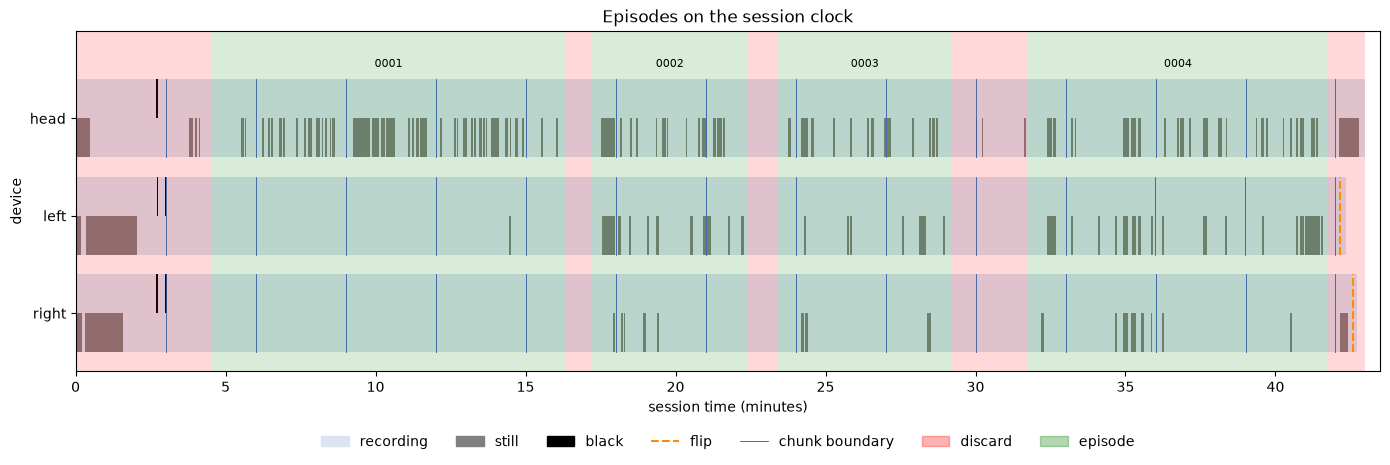

saved 05_episode_timeline.png


In [29]:
try:
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    fig, ax = plt.subplots(figsize=(14, 4.8))
    ypos = {"head": 3, "left": 2, "right": 1}
    for d in DEVICES:
        y = ypos[d]
        t0, t1 = dev_start[d] / 60, dev_end[d] / 60
        ax.broken_barh([(t0, t1 - t0)], (y - 0.4, 0.8), facecolors="#dbe4f0")
        if cand is not None:
            c = cand[cand["device"] == d]
            still = [(r.start_s / 60, r.duration_s / 60) for r in c[c["kind"] == "still"].itertuples()]
            blk = [(r.start_s / 60, r.duration_s / 60) for r in c[c["kind"] == "black"].itertuples()]
            if still:
                ax.broken_barh(still, (y - 0.4, 0.4), facecolors="#808080")
            if blk:
                ax.broken_barh(blk, (y, 0.4), facecolors="black")
            for r in c[c["kind"] == "flip"].itertuples():
                ax.plot([r.start_s / 60] * 2, [y - 0.4, y + 0.4], color="darkorange", ls="--", lw=1.5)
        for s0 in chunk_tab[d]["start_s"]:
            ax.plot([s0 / 60] * 2, [y - 0.4, y + 0.4], color="#2c5aa0", lw=0.6)

    if have_cuts and eps is not None:
        for r in discards.itertuples():
            ax.axvspan(r.start_s / 60, r.stop_s / 60, color="red", alpha=0.15, lw=0)
        for r in eps.itertuples():
            ax.axvspan(r.start_s / 60, r.stop_s / 60, color="green", alpha=0.15, lw=0)
            ax.text((r.start_s + r.stop_s) / 120, 3.5, r.task_id or r.id, ha="center", va="bottom", fontsize=8)
        title = "Episodes on the session clock"
    else:
        for val, name in ((suggest_setup_end, "set-up end"), (suggest_teardown_start, "tear-down start")):
            if val is not None:
                ax.axvline(val / 60, color="red", ls=":", lw=1.5)
                ax.text(val / 60, 3.5, name, color="red", fontsize=8, ha="center", va="bottom")
        title = "Candidate boundaries on the session clock (no cut list yet)"

    ax.set_yticks([3, 2, 1])
    ax.set_yticklabels(DEVICES)
    ax.set_ylim(0.4, 3.9)
    ax.set_xlim(0, max(dev_end.values()) / 60 + 0.5)
    ax.set_xlabel("session time (minutes)")
    ax.set_ylabel("device")
    ax.set_title(title)
    handles = [Patch(color="#dbe4f0", label="recording"), Patch(color="#808080", label="still"),
               Patch(color="black", label="black"), Line2D([0], [0], color="darkorange", ls="--", label="flip"),
               Line2D([0], [0], color="#2c5aa0", lw=0.6, label="chunk boundary")]
    if have_cuts and eps is not None:
        handles += [Patch(color="red", alpha=0.3, label="discard"), Patch(color="green", alpha=0.3, label="episode")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=7, frameon=False)
    fig.tight_layout()
    fig.savefig(reports / "05_episode_timeline.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved 05_episode_timeline.png")
except Exception as err:
    fail(10, err)

## Step 11 - Summary and zip
Saves a small summary file, zips every 05_ file in reports for sharing, and prints the result in plain text.

In [30]:
try:
    summary = {
        "session_zero_us": session_zero,
        "devices": {d: {"frames": len(tl[d]["n"]), "start_s": dev_start[d], "end_s": dev_end[d]} for d in tl},
        "seams_measured": None if seam_df is None else len(seam_df),
        "seam_max_ratio": None if seam_df is None or not len(seam_df) else float(seam_df["ratio"].max()),
        "candidates": None if cand is None else cand.groupby("kind").size().to_dict(),
        "suggested_setup_end_s": suggest_setup_end,
        "suggested_teardown_start_s": suggest_teardown_start,
        "cut_list_found": have_cuts,
        "episodes": None if eps is None else len(eps),
        "episodes_total_s": None if eps is None else float(eps["duration_s"].sum()),
        "hypotheses": None if "hyp" not in globals() else hyp[["id", "result"]].set_index("id")["result"].to_dict(),
    }
    (reports / "05_summary.json").write_text(json.dumps(plain(summary), indent=2), encoding="utf-8")

    zip_path = reports / "share_05.zip"
    files = sorted(p for p in reports.glob("05_*") if p.is_file())
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in files:
            zf.write(p, p.name)
    print(f"zip: {zip_path.name} with {len(files)} files")

    print()
    print("summary")
    for d in tl:
        print(f"  {d}: {len(tl[d]['n'])} frames, {len(tl[d]['n']) / FPS / 60:.2f} min")
    if seam_df is not None and len(seam_df):
        print(f"  seams: {len(seam_df)} measured, largest ratio {seam_df['ratio'].max():.2f}")
    print("  suggested set-up end:", None if suggest_setup_end is None else f"{suggest_setup_end:.1f} s")
    print("  suggested tear-down start:", None if suggest_teardown_start is None else f"{suggest_teardown_start:.1f} s")
    if have_cuts and eps is not None:
        print(f"  cut list: {len(eps)} episodes, {eps['duration_s'].sum() / 60:.1f} min in total")
    else:
        print("  cut list: not found yet, fill in the template and run again")
except Exception as err:
    fail(11, err)

zip: share_05.zip with 8 files

summary
  head: 77371 frames, 42.98 min
  left: 76254 frames, 42.36 min
  right: 76882 frames, 42.71 min
  seams: 42 measured, largest ratio 3.02
  suggested set-up end: 182.5 s
  suggested tear-down start: None
  cut list: 4 episodes, 32.8 min in total
